# 02 — Computer Vision Pipeline: Reference Frame & 3-Point Thigh Anchor Selection

This notebook details the **2D Computer Vision & Anatomical Geometry Pipeline** that initializes 3D tracking on the subject's right thigh (femur).

### Pipeline Stages Covered:
1. **Multi-Factor Reference Frame Selection (`ReferenceFrameFinder`)**: Scanning the OpenPose 2D keypoint sequence to identify the optimal double-support frame where stride separation is maximized and self-occlusion is absent.
2. **Anatomical Femur Basis & Strip Geometry (`VectorMath`)**: Constructing the local orthogonal coordinate frame $(\mathbf{u}, \mathbf{u}_{\perp})$ along the Knee-to-Hip axis and isolating the lower-third thigh fascia ($0 \le d_{\parallel} \le 0.35\,\|\mathbf{v}_{\text{femur}}\|$).
3. **Directional Sobel Edge Detection & Huber M-Estimator Line Fitting (`ThighEdgeDetector`, `RobustLineFitter`)**: Extracting anterior/posterior thigh boundaries while rejecting loose clothing outliers.
4. **Inward Safety Erosion & 3-Point Anatomical Triangle Placement (`FemurVisionOrchestrator`)**: Applying a 2-pixel inward safety margin and placing the non-collinear anchor triangle $(P_1, P_2, P_3)$.

In [1]:
import os
import sys
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "examples" else current_dir
os.chdir(str(project_root))
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

plt.rcParams["figure.dpi"] = 110
print(f"Workspace initialized: {project_root.name}")

Workspace initialized: monocular-3d-gait-tracking-deltav2


## 1. Reference Frame Selection (Multi-Factor Double-Support Strategy)

### Conceptual Logic
Initializing dense 3D point tracking requires an unambiguous, unoccluded view of the right thigh. While **maximum horizontal knee separation** (double-support phase) is the primary signal, `ref_frame_finder` enforces three strict geometric constraints:
1. **Maximum Stride Peaks**: Identifies local maxima of the inter-knee distance $|x_{\text{RKnee}}(t) - x_{\text{LKnee}}(t)|$.
2. **Segment-Intersection Crossover Check**: Verifies that the 2D femur segments (`RHip`–`RKnee` and `LHip`–`LKnee`) do not intersect, preventing initialization during contralateral leg occlusion.
3. **Boundary & Confidence Guard**: Ensures all lower-body joints exceed confidence thresholds and lie safely inside the camera field of view.

Optimal Reference Frame Selected: Frame #19 / 302 (30.0 FPS)


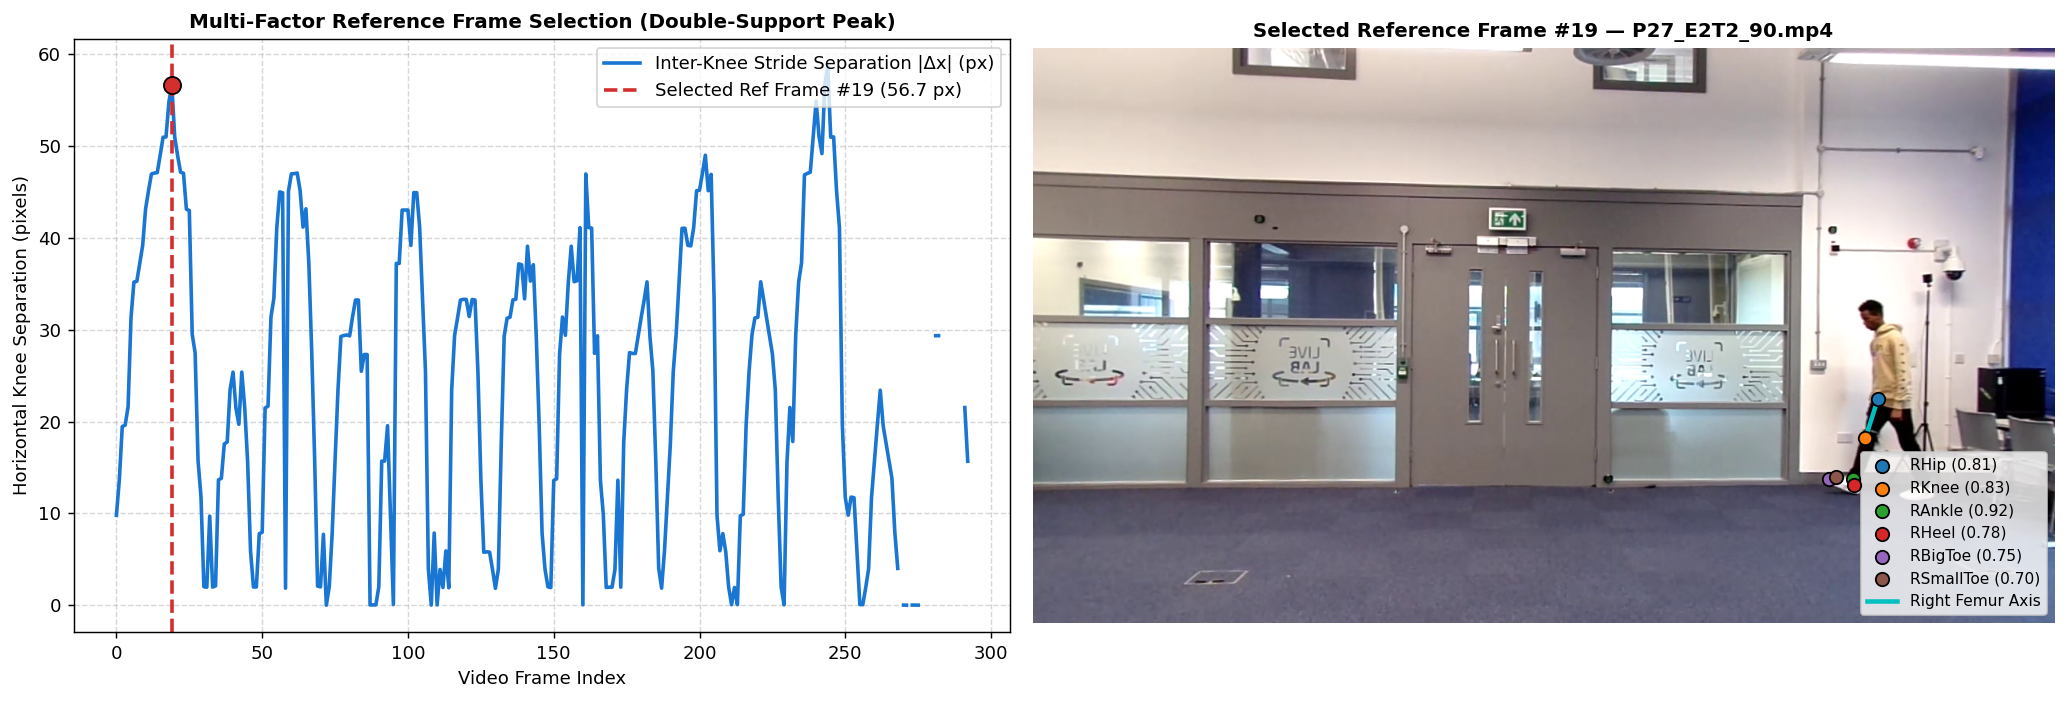

In [2]:
from src.data_io.dataset_scanner import DatasetScanner
from src.data_io.video_reader import video_provider
from src.data_io.openpose_reader import openpose_reader
from src.preprocessing.vision.frame_selection import ref_frame_finder

scanner = DatasetScanner(str(project_root / "data"))
video_info = next(v for v in scanner if v.name == "P27_E2T2_90.mp4")
metadata = video_provider.get_metadata(project_root / video_info.video_path)
res = ref_frame_finder.find_specific_keypoints_ref(video_info, metadata)
ref_idx = res["ref_frame_idx"]

# Compute inter-knee horizontal stride separation across all frames for visualization
stride_widths = []
valid_frames = sorted(int(k) for k in video_info.keypoints_map.keys())
for f_idx in valid_frames:
    kps = openpose_reader.load_frame_keypoints(project_root / video_info.keypoints_map[str(f_idx)])
    if kps and "RKnee" in kps and "LKnee" in kps and kps["RKnee"][2] > 0.1 and kps["LKnee"][2] > 0.1:
        stride_widths.append((f_idx, abs(kps["RKnee"][0] - kps["LKnee"][0])))
    else:
        stride_widths.append((f_idx, np.nan))
stride_df = np.array(stride_widths)

frame_bgr, _ = video_provider.get_frame(project_root / video_info.video_path, ref_idx)
frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.1, 1.2]})
ax1.plot(stride_df[:, 0], stride_df[:, 1], color="#1976D2", lw=2.0, label="Inter-Knee Stride Separation |Δx| (px)")
ref_sep = stride_df[stride_df[:, 0] == ref_idx, 1][0]
ax1.axvline(ref_idx, color="#D32F2F", ls="--", lw=2.0, label=f"Selected Ref Frame #{ref_idx} ({ref_sep:.1f} px)")
ax1.scatter([ref_idx], [ref_sep], color="#D32F2F", s=90, zorder=10, edgecolors="black")
ax1.set_title("Multi-Factor Reference Frame Selection (Double-Support Peak)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Video Frame Index")
ax1.set_ylabel("Horizontal Knee Separation (pixels)")
ax1.legend(loc="upper right")
ax1.grid(True, ls="--", alpha=0.5)

ax2.imshow(frame_rgb)
pts = res["keypoints"]
for j_name, j_val in pts.items():
    ax2.scatter(j_val["x"], j_val["y"], s=55, label=f"{j_name} ({j_val['confidence']:.2f})", edgecolors="black", zorder=6)
ax2.plot([pts["RHip"]["x"], pts["RKnee"]["x"]], [pts["RHip"]["y"], pts["RKnee"]["y"]], "c-", lw=2.5, label="Right Femur Axis")
ax2.set_title(f"Selected Reference Frame #{ref_idx} — {video_info.name}", fontsize=11, fontweight="bold")
ax2.legend(loc="lower right", fontsize=8.5)
ax2.axis("off")

plt.tight_layout()
plt.show()
print(f"Optimal Reference Frame Selected: Frame #{ref_idx} / {metadata.frames_num} ({metadata.fps:.1f} FPS)")

## 2. Step-by-Step Anatomical & Geometric Pipeline

To isolate the thigh surface and place an anatomically locked 3-point triangle $(P_1, P_2, P_3)$ without capturing background pixels or knee-joint skin folding, `FemurVisionOrchestrator` executes six geometric steps:

1. **Femur Orthonormal Basis ($\mathbf{u}, \mathbf{u}_{\perp}$)**: Given $\mathbf{p}_{\text{knee}}$ and $\mathbf{p}_{\text{hip}}$, the unit longitudinal vector $\mathbf{u} = \frac{\mathbf{p}_{\text{hip}} - \mathbf{p}_{\text{knee}}}{\|\mathbf{v}_{\text{femur}}\|}$ and transverse normal $\mathbf{u}_{\perp} = (-u_y, u_x)^\top$ define local thigh coordinates $(d_{\parallel}, d_{\perp})$.
2. **Lower-Third Fascia (Strip) Mask**: Restricts search to $0 \le d_{\parallel} \le 0.35\,\|\mathbf{v}_{\text{femur}}\|$ above the knee joint.
3. **Bounding Box Formation**: Clips transverse width to $|d_{\perp}| \le \text{THIGH\_WIDTH\_FACTOR} \cdot \|\mathbf{v}_{\text{femur}}\|$.
4. **Directional Sobel Gradients & Huber M-Estimator Line Fitting**: Detects left (anterior) and right (posterior) limb edges and fits bounded lines robust to loose clothing outliers.
5. **2-Pixel Inward Safety Erosion (`SAFETY_MARGIN_PX = 2`)**: Erodes the segmented thigh polygon inward so boundary points never sample the background depth cliff.
6. **3-Point Triangle Placement ($P_1, P_2, P_3$)**:
   - $P_1$: Shifted from the knee joint toward the hip along $\mathbf{u}$ by `KNEE_OFFSET_FACTOR`.
   - $P_2, P_3$: Placed near the anterior and posterior eroded boundaries in the lower third of the thigh.

In [3]:
from src.preprocessing.vision.line_fitting import RobustLineFitter
from src.preprocessing.vision.edge_processing import ThighEdgeDetector
from src.preprocessing.vision.vision_orchestrator import FemurVisionOrchestrator
from src.preprocessing.vision.geometry import VectorMath
from src.core.constants import THIGH_WIDTH_FACTOR, SAFETY_MARGIN_PX, KNEE_OFFSET_FACTOR

# --- 1. EXPLICIT STEP-BY-STEP GEOMETRIC COMPUTATION ---
points = res["keypoints"]
p_hip = np.array([points["RHip"]["x"], points["RHip"]["y"]])
p_knee = np.array([points["RKnee"]["x"], points["RKnee"]["y"]])

v_mag, u, u_perp, v_femur = VectorMath.calculate_femur_basis(p_knee, p_hip)
h, w = frame_bgr.shape[:2]
long_dist, trans_proj, trans_dist = VectorMath.create_relative_mesh(h, w, p_knee, u, u_perp)

# Step 1 & 2: Lower-third fascia strip and transverse bounding box
strip_mask = (long_dist >= 0) & (long_dist <= v_mag * 0.35)
width_limit = THIGH_WIDTH_FACTOR * v_mag
bbox_mask = strip_mask & (trans_dist <= width_limit)

# Step 3 & 4: Directional edge detection and robust Huber M-estimator line fitting
edge_detector = ThighEdgeDetector()
line_fitter = RobustLineFitter()
left_pts, right_pts = edge_detector.detect_edges(
    frame_bgr, u_perp, long_dist, trans_proj, trans_dist, width_limit, v_mag
)
line_l = line_fitter.fit_bounded_line(left_pts, u)
line_r = line_fitter.fit_bounded_line(right_pts, u)

# Step 5 & 6: Outer/inner eroded masks and final 3-point triangle composition
vision_orchestrator = FemurVisionOrchestrator()
triangle, mask_outer, mask_inner = vision_orchestrator.compose(points, frame_bgr)

print(f"Femur Pixel Length ||v_femur|| : {v_mag:.1f} px")
print(f"Detected Edge Candidates       : Left={len(left_pts)} pts | Right={len(right_pts)} pts")
print(f"Outer vs Eroded Mask Area      : Outer={int(np.sum(mask_outer > 0))} px² -> Inner={int(np.sum(mask_inner > 0))} px²")
for idx_pt, pt in enumerate(triangle, 1):
    print(f"  Anchor P{idx_pt}: (x={pt[0]:.1f}, y={pt[1]:.1f})")

Femur Pixel Length ||v_femur|| : 51.4 px
Detected Edge Candidates       : Left=15 pts | Right=15 pts
Outer vs Eroded Mask Area      : Outer=353 px² -> Inner=282 px²
  Anchor P1: (x=1044.4, y=483.4)
  Anchor P2: (x=1047.0, y=473.0)
  Anchor P3: (x=1050.0, y=482.0)


## 3. Six-Stage Geometric Visualization on the Thigh Region

The 2×3 panel below visualizes each of the 6 geometric stages zoomed directly onto the subject's right thigh.

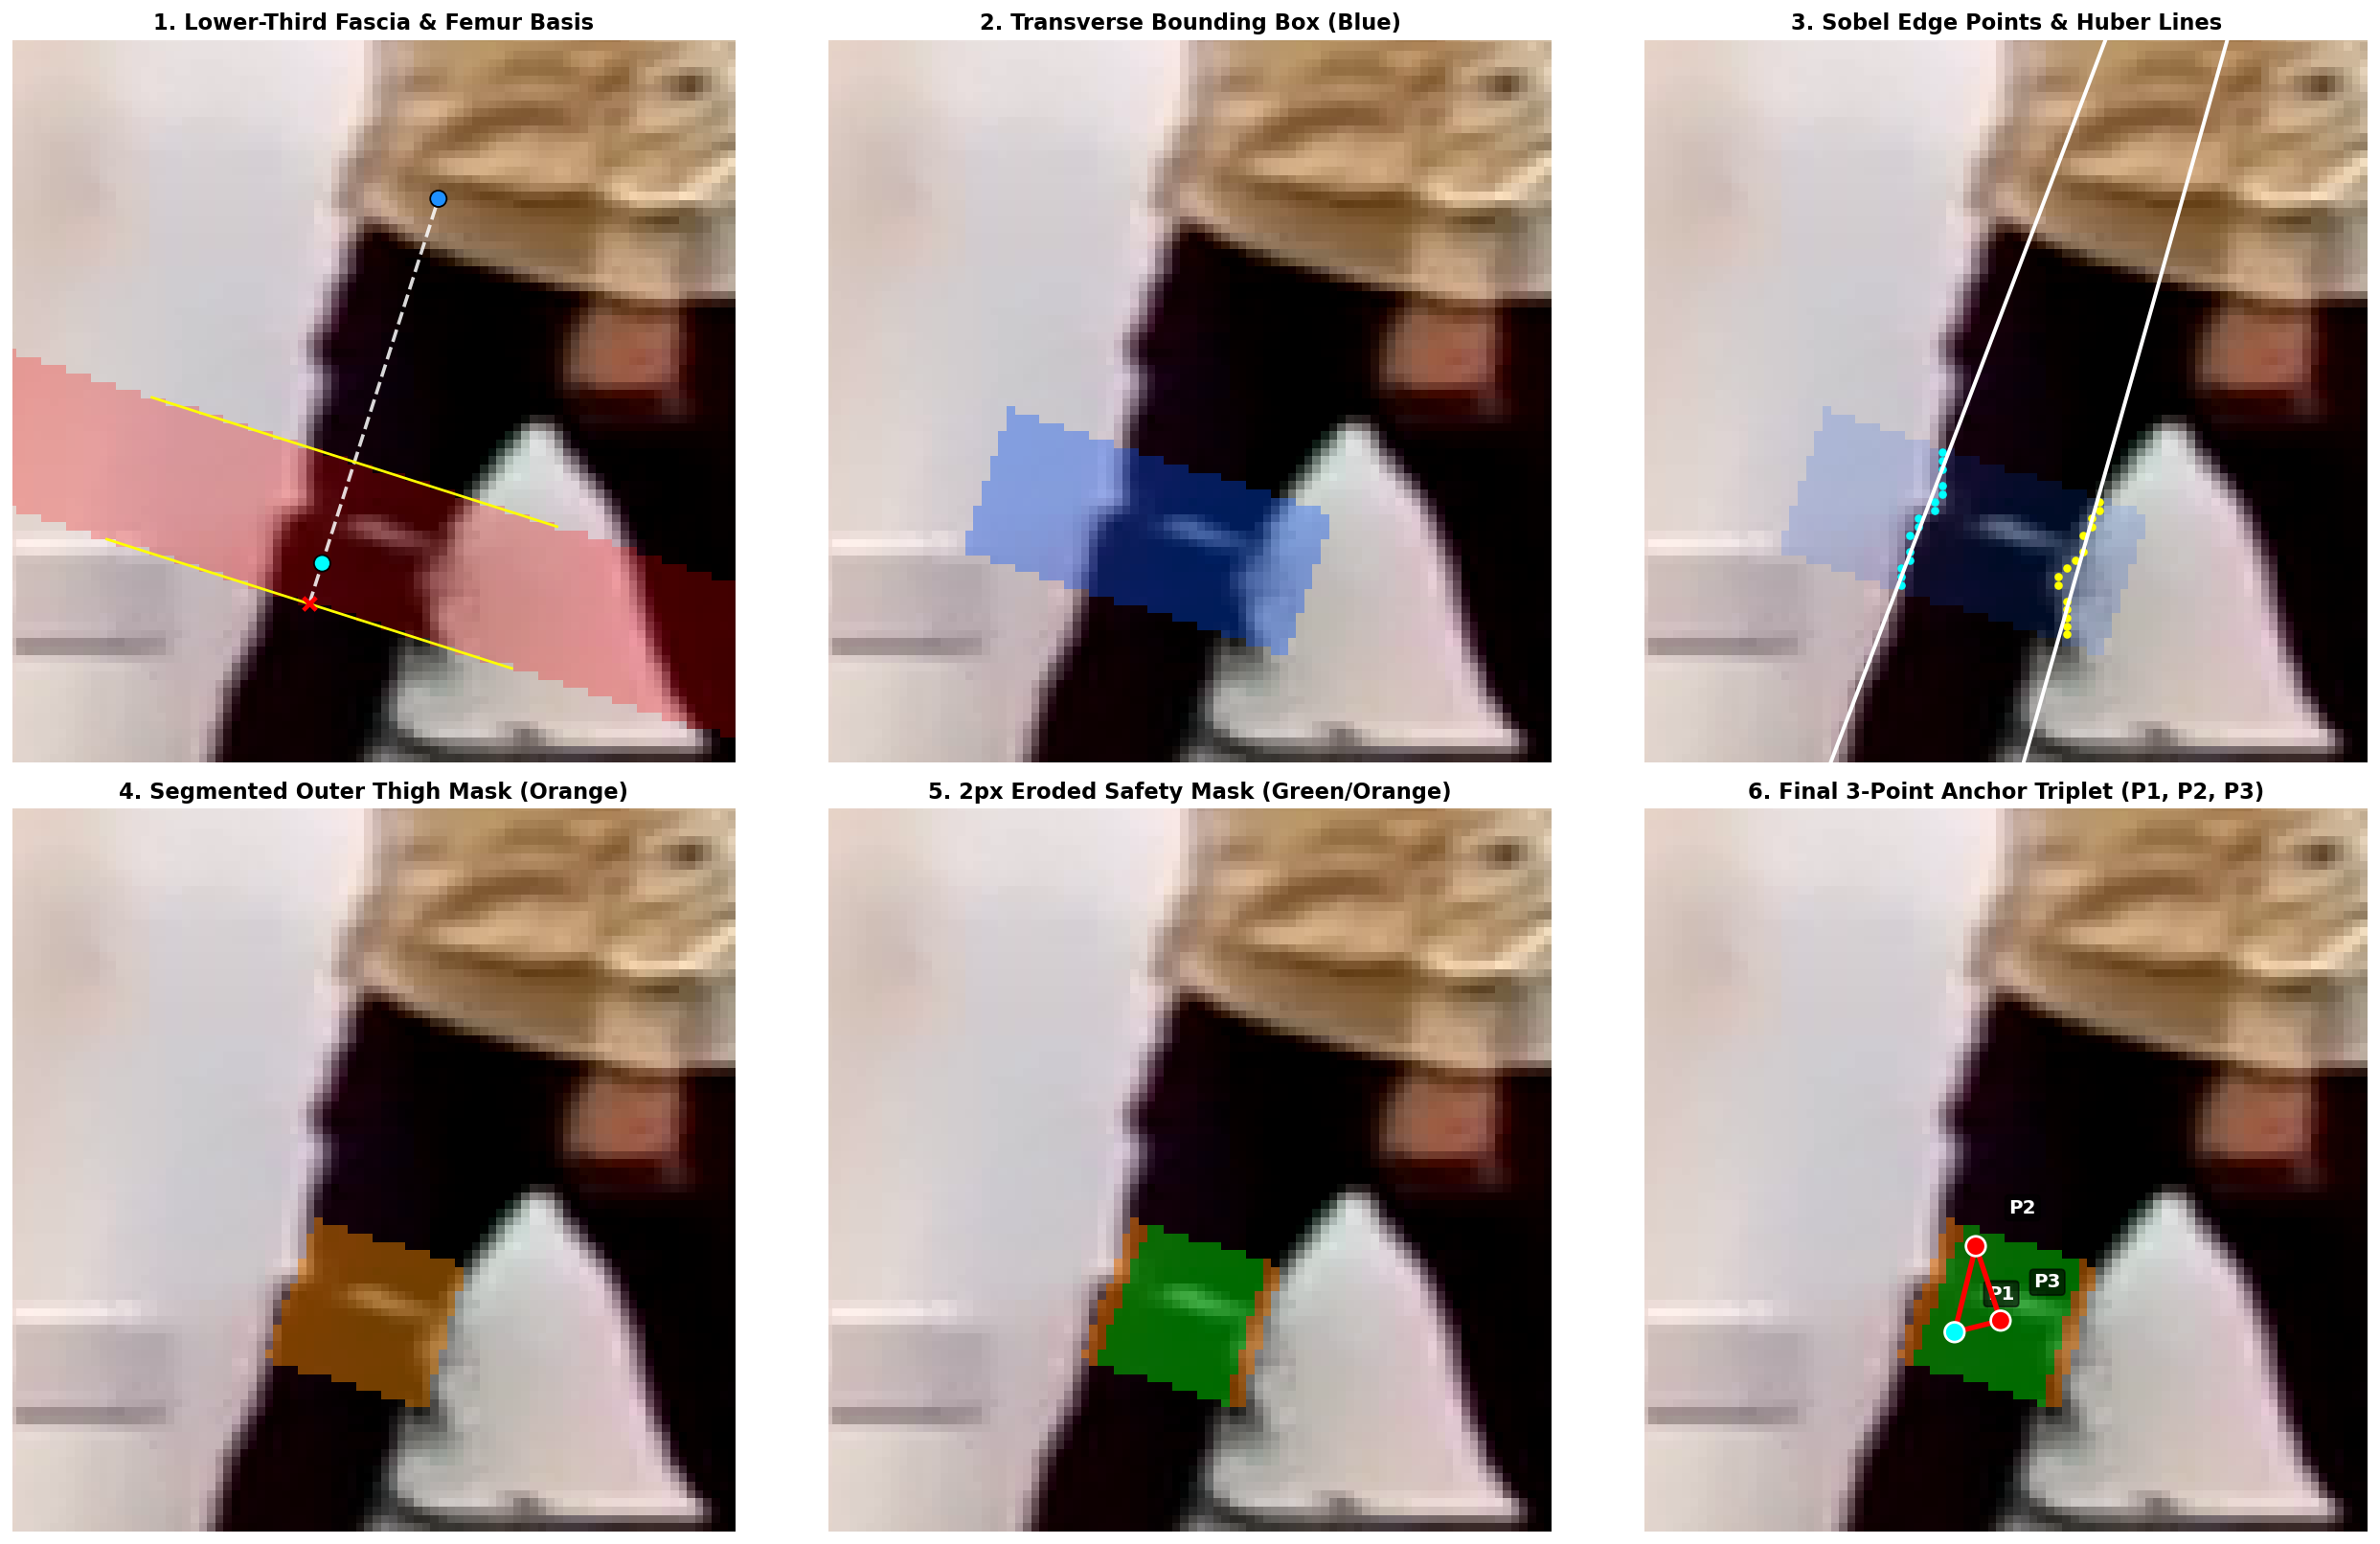

In [4]:
def apply_ov(img, m, c, a=0.35):
    """Apply a colored alpha overlay onto an RGB image where mask m > 0."""
    out = img.copy()
    if m is not None and np.any(m):
        out[m > 0] = (out[m > 0] * (1 - a) + np.array(c) * a).astype(np.uint8)
    return out

fig, axes = plt.subplots(2, 3, figsize=(20, 12.5))
axes = axes.flatten()

# Zoom window centered on the femur
z_c = (p_knee + p_hip) / 2.0
z_r = v_mag * 0.85
xl, yl = (z_c[0] - z_r, z_c[0] + z_r), (z_c[1] + z_r, z_c[1] - z_r)

def setup_zoom_ax(ax, title):
    ax.set(xlim=xl, ylim=yl)
    ax.set_title(title, fontsize=12.5, fontweight="bold")
    ax.axis("off")

# Panel 1: Fascia & Basis Geometry
axes[0].imshow(apply_ov(frame_rgb, strip_mask, (255, 0, 0), 0.25))
axes[0].plot([p_knee[0], p_hip[0]], [p_knee[1], p_hip[1]], "w--", lw=2.0, alpha=0.85, label="Femur Axis")
p1_shifted = p_knee + u * (v_mag * KNEE_OFFSET_FACTOR)
axes[0].scatter([p1_shifted[0], p_hip[0]], [p1_shifted[1], p_hip[1]], c=["cyan", "dodgerblue"], s=90, edgecolors="black", zorder=5)
axes[0].scatter(p_knee[0], p_knee[1], c="red", s=55, marker="x", lw=2.5, zorder=6)
t_span = np.array([-0.5, 0.5]) * v_mag
for pb in [p_knee, p_knee + u * (v_mag * 0.35)]:
    axes[0].plot(pb[0] + t_span * u_perp[0], pb[1] + t_span * u_perp[1], "yellow", lw=1.5)
setup_zoom_ax(axes[0], "1. Lower-Third Fascia & Femur Basis")

# Panel 2: Transverse Bounding Box
axes[1].imshow(apply_ov(frame_rgb, bbox_mask, (0, 80, 255), 0.35))
setup_zoom_ax(axes[1], "2. Transverse Bounding Box (Blue)")

# Panel 3: Edge Points & Robust Huber Lines
axes[2].imshow(apply_ov(frame_rgb, bbox_mask, (0, 80, 255), 0.15))
for pts_arr, col_c in [(np.array(left_pts), "yellow"), (np.array(right_pts), "cyan")]:
    if pts_arr.size:
        axes[2].scatter(pts_arr[:, 0], pts_arr[:, 1], c=col_c, s=14, zorder=4)
for ln in [line_l, line_r]:
    if ln is not None:
        vx, vy, x0, y0 = ln
        tt = np.linspace(-100, 100, 2)
        axes[2].plot(x0 + tt * vx, y0 + tt * vy, "w-", lw=2.2, zorder=5)
setup_zoom_ax(axes[2], "3. Sobel Edge Points & Huber Lines")

# Panel 4: Trimmed Outer Thigh Mask
axes[3].imshow(apply_ov(frame_rgb, mask_outer, (255, 140, 0), 0.45))
setup_zoom_ax(axes[3], "4. Segmented Outer Thigh Mask (Orange)")

# Panel 5 & 6: Eroded Inner Safety Mask & Final 3-Point Anchor Triangle
ov_eroded = np.zeros((*frame_rgb.shape[:2], 4), dtype=np.float32)
ov_eroded[mask_inner > 0] = [0.0, 1.0, 0.0, 0.42]
ov_eroded[(mask_outer > 0) & (mask_inner == 0)] = [1.0, 0.5, 0.0, 0.48]

for idx_p, title_p in [(4, "5. 2px Eroded Safety Mask (Green/Orange)"), (5, "6. Final 3-Point Anchor Triplet (P1, P2, P3)")]:
    axes[idx_p].imshow(frame_rgb)
    axes[idx_p].imshow(ov_eroded)
    if idx_p == 5:
        tri_np = np.array(triangle)
        tri_closed = np.vstack([tri_np, tri_np[0]])
        axes[5].plot(tri_closed[:, 0], tri_closed[:, 1], "r-", lw=3.0, zorder=9)
        axes[5].scatter(tri_np[:, 0], tri_np[:, 1], c=["cyan", "red", "red"], s=130, edgecolors="white", lw=1.5, zorder=10)
        for k_i, (kx, ky) in enumerate(tri_np, 1):
            axes[5].text(kx + 4, ky - 4, f"P{k_i}", color="white", fontsize=11, fontweight="bold", bbox=dict(boxstyle="round,pad=0.2", fc="black", alpha=0.6))
    setup_zoom_ax(axes[idx_p], title_p)

plt.tight_layout()
plt.show()